# Latihan 7 : Logit Biner
### 1. Import Library

In [19]:
import pandas as pd 
from imblearn.over_sampling import RandomOverSampler 
from collections import Counter
from sklearn.model_selection import train_test_split 
import matplotlib.pyplot as plt

### 2. Membuka Dataset

In [20]:
dataset = pd.read_csv("../data/klasifikasi__UKT_komplit.csv") 
dataset.head(10)

,No.,StatusOrtu,Penghasilan,Status_Rumah,JMotor,Jmobil,DayaLis,KIPK
0,1,1,4000000,1,1,0,2,0
1,2,1,2500000,0,1,0,3,0
2,3,1,6000000,1,2,0,2,0
3,4,1,5440500,1,2,0,2,0
4,5,1,10000000,0,1,1,3,0
5,6,1,1000000,0,1,0,3,1
6,7,1,20000000,1,2,1,3,0
7,8,1,15000000,1,1,0,3,0
8,9,4,4000000,1,1,1,3,0
9,10,1,0,1,2,0,1,0


### 3. Statistik Deskriptif

In [21]:
def show_info(dataset):
    dataset.info()
    del(dataset['No.'])
    dataset.describe

In [22]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1707 entries, 0 to 1706
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   No.           1707 non-null   int64
 1   StatusOrtu    1707 non-null   int64
 2   Penghasilan   1707 non-null   int64
 3   Status_Rumah  1707 non-null   int64
 4   JMotor        1707 non-null   int64
 5   Jmobil        1707 non-null   int64
 6   DayaLis       1707 non-null   int64
 7   KIPK          1707 non-null   int64
dtypes: int64(8)
memory usage: 106.8 KB


In [23]:
dataset.describe()

,No.,StatusOrtu,Penghasilan,Status_Rumah,JMotor,Jmobil,DayaLis,KIPK
count,1707.000000,1707.000000,1.707000e+03,1707.000000,1707.000000,1707.000000,1707.000000,1707.000000
mean,854.000000,1.164030,5.195012e+06,0.807264,1.968366,0.357938,2.205038,0.157586
std,492.912771,0.565764,5.552922e+06,0.394563,0.823274,0.541534,0.676276,0.364460
min,1.000000,1.000000,-1.000000e+06,0.000000,0.000000,0.000000,1.000000,0.000000
25%,427.500000,1.000000,2.000000e+06,1.000000,1.000000,0.000000,2.000000,0.000000
50%,854.000000,1.000000,4.000000e+06,1.000000,2.000000,0.000000,2.000000,0.000000
75%,1280.500000,1.000000,6.131916e+06,1.000000,2.000000,1.000000,3.000000,0.000000
max,1707.000000,4.000000,7.300000e+07,1.000000,5.000000,3.000000,3.000000,1.000000


In [24]:
del(dataset["No."]) 
dataset.describe()

,StatusOrtu,Penghasilan,Status_Rumah,JMotor,Jmobil,DayaLis,KIPK
count,1707.000000,1.707000e+03,1707.000000,1707.000000,1707.000000,1707.000000,1707.000000
mean,1.164030,5.195012e+06,0.807264,1.968366,0.357938,2.205038,0.157586
std,0.565764,5.552922e+06,0.394563,0.823274,0.541534,0.676276,0.364460
min,1.000000,-1.000000e+06,0.000000,0.000000,0.000000,1.000000,0.000000
25%,1.000000,2.000000e+06,1.000000,1.000000,0.000000,2.000000,0.000000
50%,1.000000,4.000000e+06,1.000000,2.000000,0.000000,2.000000,0.000000
75%,1.000000,6.131916e+06,1.000000,2.000000,1.000000,3.000000,0.000000
max,4.000000,7.300000e+07,1.000000,5.000000,3.000000,3.000000,1.000000


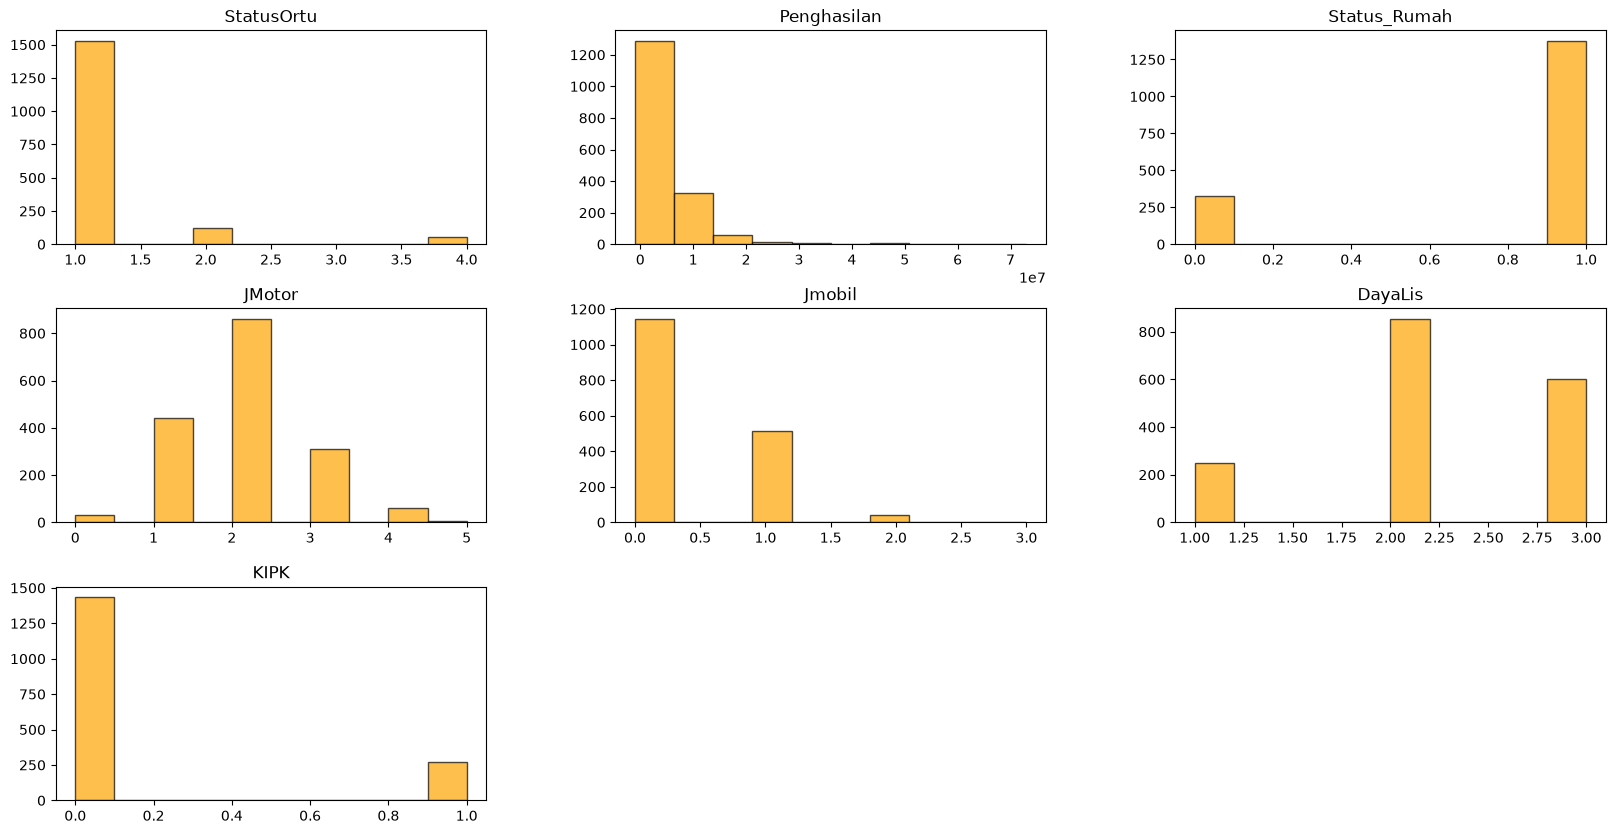

In [25]:
dataset.hist(figsize=(20,10),alpha = 0.7, color = 'orange',edgecolor ='black',grid=False);

### 4. Normalisasi data dan oversampling

In [26]:
from sklearn.preprocessing import MinMaxScaler 
array = dataset.values 
X = array[:,1:6] #slicing dataframe ke dalam array 
y = array[:,6] 

In [27]:
y = y.astype('int')
print(y)

[0 0 0 ... 0 0 0]


In [28]:
print(Counter(y))

Counter({np.int64(0): 1438, np.int64(1): 269})


In [29]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

scaler = MinMaxScaler() # transform data 
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test) 
print(X)

[[4000000       1       1       0       2]
 [2500000       0       1       0       3]
 [6000000       1       2       0       2]
 ...
 [ 900000       1       3       1       2]
 [5000000       0       2       0       1]
 [8000000       1       3       0       2]]


In [30]:
# instantiating the random over sampler 
ros = RandomOverSampler()

# resampling x_train, y_train 
X_ros, y_ros = ros.fit_resample(x_train, y_train) 

# new class distribution 
print(Counter(y_ros))

Counter({np.int64(0): 1156, np.int64(1): 1156})


### 5. Import Library 2

In [31]:
from sklearn.metrics import classification_report 
from sklearn.metrics import confusion_matrix,accuracy_score
from sklearn.linear_model import LogisticRegression 

logmodel = LogisticRegression()

### 6.a Model-1 dengan data asli

In [37]:
model1=logmodel.fit(x_train, y_train) 
predictions1a = model1.predict(x_train) 
predictions1b = model1.predict(x_test) 
predictions1c = model1.predict_proba(x_test)[:,1] 
print("-------Model-1: Logistic Regression using Real Data (Train)-------") 
print("Kinerja Data Training:") 
print(classification_report(y_train, predictions1a))
print("Mariks Konfusi dari Model-1 Train:")  
print(confusion_matrix(y_train, predictions1a))
print("Nilai Akurasi Model-1 Train:") 
print(accuracy_score(y_train, predictions1a)) 

-------Model-1: Logistic Regression using Real Data (Train)-------
Kinerja Data Training:
              precision    recall  f1-score   support

           0       0.85      0.99      0.92      1156
           1       0.48      0.06      0.11       209

    accuracy                           0.85      1365
   macro avg       0.67      0.53      0.51      1365
weighted avg       0.80      0.85      0.79      1365

Mariks Konfusi dari Model-1 Train:
[[1142   14]
 [ 196   13]]
Nilai Akurasi Model-1 Train:
0.8461538461538461


In [33]:
print("-------Model-1: Logistic Regression using Real Dataset (Test)-------") 
print("Kinerja Data Testing:") 
print(classification_report(y_test, predictions1b))
print("Mariks Konfusi dari Model-1 Test:") 
print(confusion_matrix(y_test, predictions1b))
print("Nilai Akurasi Model-1 Test:") 
print(accuracy_score(y_test, predictions1b))

-------Model-1: Logistic Regression using Real Dataset (Test)-------
Kinerja Data Testing:
              precision    recall  f1-score   support

           0       0.83      0.98      0.90       282
           1       0.33      0.05      0.09        60

    accuracy                           0.82       342
   macro avg       0.58      0.51      0.49       342
weighted avg       0.74      0.82      0.76       342

Mariks Konfusi dari Model-1 Test:
[[276   6]
 [ 57   3]]
Nilai Akurasi Model-1 Test:
0.8157894736842105


### 6.b Model-2 dengan data oversampling

In [ ]:
model2=logmodel.fit(X_ros, y_ros) 
predictions2a = model2.predict(X_ros) 
predictions2b = model2.predict(x_test) 
predictions2c = model2.predict_proba(x_test)[:,1] 
print("-------Model-2: Logistic Regression with Random Oversampling (Train)-------") 
print("Kinerja Data Training:") 
print(classification_report(y_ros, predictions2a))
print("Mariks Konfusi dari Model-2 Train:") 
print(confusion_matrix(y_ros, predictions2a))
print("Nilai Akurasi Model-2 Train:") 
print(accuracy_score(y_ros, predictions2a)) 

-------Model-2: Logit Biner dengan Dataset Over-sampling (Train)-------
Kinerja Data Training:
              precision    recall  f1-score   support

           0       0.80      0.71      0.75      1156
           1       0.74      0.83      0.78      1156

    accuracy                           0.77      2312
   macro avg       0.77      0.77      0.77      2312
weighted avg       0.77      0.77      0.77      2312

Mariks Konfusi dari Model-2 Train:
[[819 337]
 [202 954]]
Nilai Akurasi Model-2 Train:
0.7668685121107266


In [35]:
print("-------Model-2: Logit Biner dengan Dataset Over-sampling (Test)-------") 
print("Kinerja Data Testing:") 
print(classification_report(y_test, predictions2b))
print("Mariks Konfusi dari Model-2 Test:") 
print(confusion_matrix(y_test, predictions2b))
print("Nilai Akurasi Model-2 Test:") 
print(accuracy_score(y_test, predictions2b))

-------Model-2: Logit Biner dengan Dataset Over-sampling (Test)-------
Kinerja Data Testing:
              precision    recall  f1-score   support

           0       0.96      0.76      0.85       282
           1       0.42      0.83      0.56        60

    accuracy                           0.77       342
   macro avg       0.69      0.80      0.70       342
weighted avg       0.86      0.77      0.80       342

Mariks Konfusi dari Model-2 Test:
[[214  68]
 [ 10  50]]
Nilai Akurasi Model-2 Test:
0.7719298245614035


### 7. Perbandingan antar model 

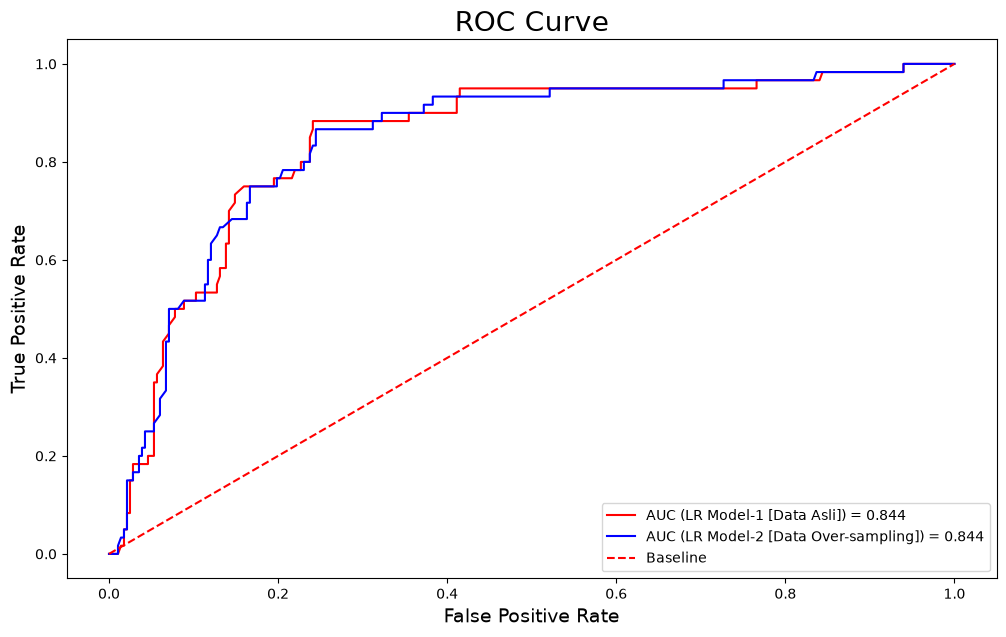

In [36]:
from sklearn.metrics import roc_auc_score, roc_curve 
auc1 = roc_auc_score(y_test, predictions1c)
fpr1, tpr1, thresholds1 = roc_curve(y_test, predictions1c) 
auc2 = roc_auc_score(y_test, predictions2c) 
fpr2, tpr2, thresholds2 = roc_curve(y_test, predictions2c) 
plt.figure(figsize=(12, 7)) 
plt.plot(fpr1, tpr1, label=f'AUC (LR Model-1 [Data Asli]) = {auc1:.3f}',color='red') 
plt.plot(fpr2, tpr2, label=f'AUC (LR Model-2 [Data Over-sampling]) = {auc2:.3f}',color='blue') 
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Baseline') 
plt.title('ROC Curve', size=20) 
plt.xlabel('False Positive Rate', size=14) 
plt.ylabel('True Positive Rate', size=14) 
plt.legend();